# Module 3 — Demand Forecasting

## Business question
How much order volume should we expect in the coming weeks — to size inventory, fleet, and
distribution centers without excess or stockouts?

## 1. Setup & imports

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

from forecasting import mape, rmse, interval_coverage

pd.set_option('display.max_columns', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


Importing plotly failed. Interactive plots will not work.


## 2. Build the daily order-volume series

In [2]:
df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='latin1')
df.columns = [c.strip() for c in df.columns]
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')

daily = df.groupby(df['order date (DateOrders)'].dt.date).size().reset_index()
daily.columns = ['ds', 'y']
daily['ds'] = pd.to_datetime(daily['ds'])
daily = daily.sort_values('ds').reset_index(drop=True)

print(f"Date range: {daily['ds'].min().date()} to {daily['ds'].max().date()} ({len(daily)} days)")
daily.head()


Date range: 2015-01-01 to 2018-01-31 (1127 days)


,ds,y
0,2015-01-01,168
1,2015-01-02,154
2,2015-01-03,179
3,2015-01-04,191
4,2015-01-05,160


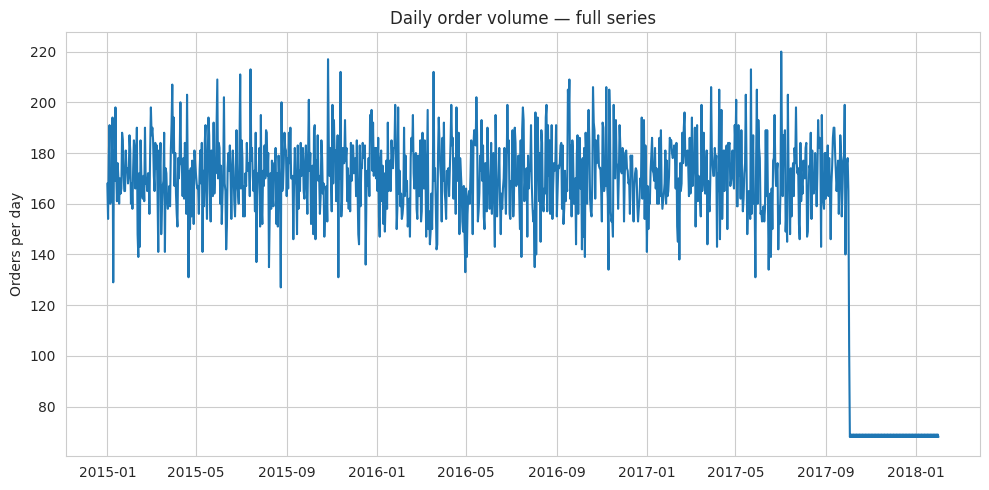

In [3]:
fig, ax = plt.subplots()
ax.plot(daily['ds'], daily['y'])
ax.set_title('Daily order volume — full series')
ax.set_ylabel('Orders per day')
plt.tight_layout()
plt.savefig('../reports/figures/module3_full_series.png', dpi=120)
plt.show()


## 3. A critical data-quality check before modeling

The plot above shows a sharp visual discontinuity in late 2017. Zoom into that window before
trusting any forecast trained across it.

In [4]:
window = daily[(daily['ds'] >= '2017-09-15') & (daily['ds'] <= '2017-10-15')]
window


,ds,y
988,2017-09-15,165
989,2017-09-16,170
990,2017-09-17,177
991,2017-09-18,156
992,2017-09-19,169
993,2017-09-20,187
994,2017-09-21,181
995,2017-09-22,155
996,2017-09-23,165
997,2017-09-24,177


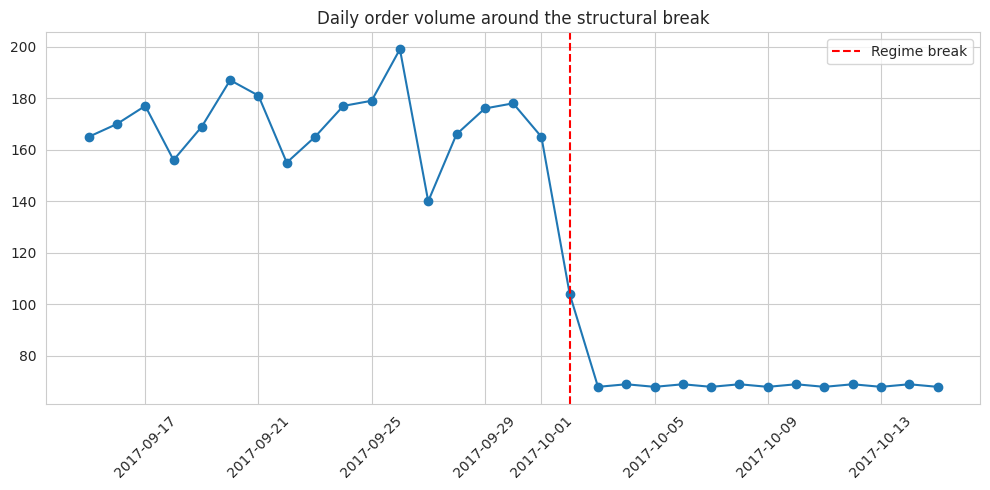

In [5]:
fig, ax = plt.subplots()
ax.plot(window['ds'], window['y'], marker='o')
ax.axvline(pd.Timestamp('2017-10-02'), color='red', linestyle='--', label='Regime break')
ax.set_title('Daily order volume around the structural break')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/figures/module3_break_zoom.png', dpi=120)
plt.show()


**Finding:** starting **2017-10-03**, daily order volume collapses from a noisy ~150–200
orders/day into a perfectly deterministic alternating 68/69 pattern that persists through the
end of the dataset (2018-01-31). A real operation does not behave this way — the pattern points to a
structural break consistent with a data-generation artifact in the later portion of this public
dataset, not a genuine demand signal.

**Decision:** the forecasting exercise below uses only the pre-break regime
(`ds <= 2017-10-01`). Training or evaluating across the break would make any model look
artificially perfect on the deterministic tail while learning nothing transferable, and would
misrepresent the real forecasting difficulty of the problem.

In [6]:
daily_clean = daily[daily['ds'] <= '2017-10-01'].reset_index(drop=True)
print(f"Clean series: {len(daily_clean)} days, {daily_clean['ds'].min().date()} to {daily_clean['ds'].max().date()}")


Clean series: 1005 days, 2015-01-01 to 2017-10-01


## 4. STL decomposition

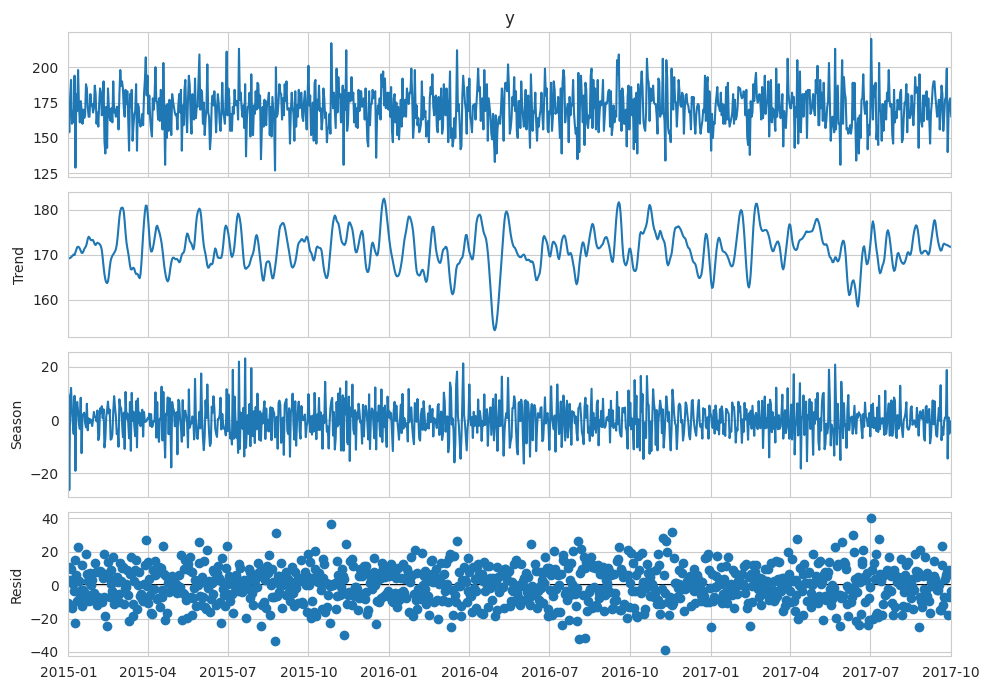

In [7]:
stl_result = STL(daily_clean.set_index('ds')['y'], period=7).fit()

fig = stl_result.plot()
fig.set_size_inches(10, 7)
plt.tight_layout()
plt.savefig('../reports/figures/module3_stl_decomposition.png', dpi=120)
plt.show()


## 5. Stationarity test (ADF)

In [8]:
adf_stat, adf_p, *_ = adfuller(daily_clean['y'])
print(f"ADF statistic: {adf_stat:.4f}")
print(f"p-value: {adf_p:.6f}")
print("Series is", "stationary" if adf_p < 0.05 else "non-stationary", "at the 5% level.")


ADF statistic: -31.3661
p-value: 0.000000
Series is stationary at the 5% level.


## 6. Train / holdout split
Chronological split — the last 30 days of the clean regime are held out, never used in training.

In [9]:
TEST_SIZE = 30
train = daily_clean.iloc[:-TEST_SIZE].reset_index(drop=True)
test = daily_clean.iloc[-TEST_SIZE:].reset_index(drop=True)
print(f"Train: {len(train)} days | Test: {len(test)} days")


Train: 975 days | Test: 30 days


## 7. Baseline: naive forecast (value from 7 days prior)

In [10]:
full_indexed = daily_clean.set_index('ds')['y']
naive_pred = full_indexed.shift(7).iloc[-TEST_SIZE:].values
naive_true = test['y'].values

naive_mape = mape(naive_true, naive_pred)
naive_rmse = rmse(naive_true, naive_pred)
print(f"Naive baseline — MAPE: {naive_mape:.2f}% | RMSE: {naive_rmse:.2f}")


Naive baseline — MAPE: 8.90% | RMSE: 18.38


## 8. SARIMA model

In [11]:
sarima_model = SARIMAX(
    train['y'], order=(1, 0, 1), seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False, enforce_invertibility=False,
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=TEST_SIZE)
sarima_pred = sarima_forecast.predicted_mean.values
sarima_ci = sarima_forecast.conf_int(alpha=0.05)

sarima_mape = mape(test['y'].values, sarima_pred)
sarima_rmse = rmse(test['y'].values, sarima_pred)
sarima_coverage = interval_coverage(test['y'].values, sarima_ci.iloc[:, 0].values, sarima_ci.iloc[:, 1].values)

print(f"SARIMA(1,0,1)(1,0,1,7) — MAPE: {sarima_mape:.2f}% | RMSE: {sarima_rmse:.2f} | 95% interval coverage: {sarima_coverage:.2%}")


SARIMA(1,0,1)(1,0,1,7) — MAPE: 6.00% | RMSE: 12.87 | 95% interval coverage: 100.00%


## 9. Prophet model

In [12]:
prophet_model = Prophet(weekly_seasonality=True, yearly_seasonality=True,
                          daily_seasonality=False, interval_width=0.95)
prophet_model.fit(train[['ds', 'y']])

future = prophet_model.make_future_dataframe(periods=TEST_SIZE)
forecast = prophet_model.predict(future)
fc_test = forecast.set_index('ds').loc[test['ds']]

prophet_mape = mape(test['y'].values, fc_test['yhat'].values)
prophet_rmse = rmse(test['y'].values, fc_test['yhat'].values)
prophet_coverage = interval_coverage(test['y'].values, fc_test['yhat_lower'].values, fc_test['yhat_upper'].values)

print(f"Prophet — MAPE: {prophet_mape:.2f}% | RMSE: {prophet_rmse:.2f} | 95% interval coverage: {prophet_coverage:.2%}")


13:14:45 - cmdstanpy - INFO - Chain [1] start processing


13:14:45 - cmdstanpy - INFO - Chain [1] done processing


Prophet — MAPE: 5.94% | RMSE: 12.78 | 95% interval coverage: 93.33%


## 10. Model comparison

In [13]:
comparison = pd.DataFrame({
    'model': ['Naive (lag-7)', 'SARIMA(1,0,1)(1,0,1,7)', 'Prophet'],
    'MAPE_%': [naive_mape, sarima_mape, prophet_mape],
    'RMSE': [naive_rmse, sarima_rmse, prophet_rmse],
})
comparison['improvement_vs_naive_%'] = (
    (comparison['MAPE_%'].iloc[0] - comparison['MAPE_%']) / comparison['MAPE_%'].iloc[0] * 100
).round(1)
comparison


,model,MAPE_%,RMSE,improvement_vs_naive_%
0,Naive (lag-7),8.904996,18.384776,0.0
1,"SARIMA(1,0,1)(1,0,1,7)",5.998736,12.873002,32.6
2,Prophet,5.940150,12.777061,33.3


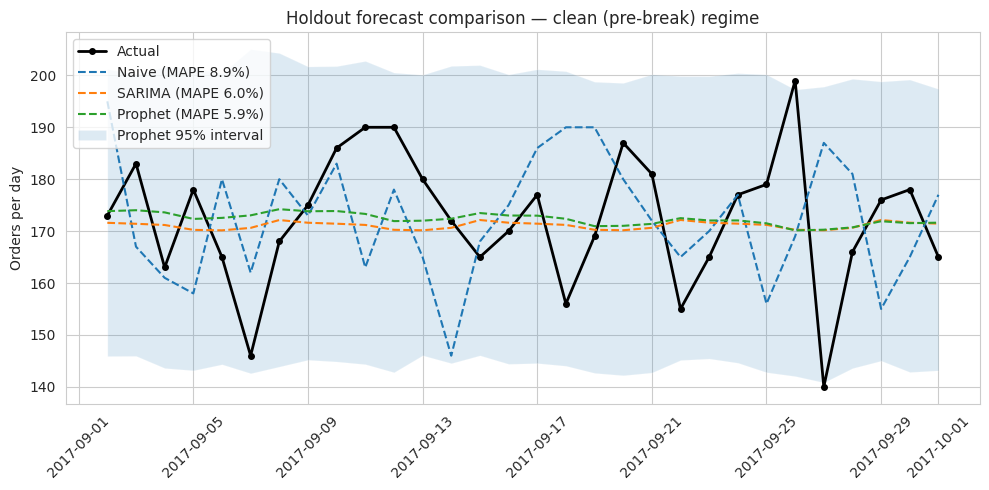

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(test['ds'], test['y'], label='Actual', color='black', linewidth=2, marker='o', markersize=4)
ax.plot(test['ds'], naive_pred, label=f'Naive (MAPE {naive_mape:.1f}%)', linestyle='--')
ax.plot(test['ds'], sarima_pred, label=f'SARIMA (MAPE {sarima_mape:.1f}%)', linestyle='--')
ax.plot(test['ds'], fc_test['yhat'].values, label=f'Prophet (MAPE {prophet_mape:.1f}%)', linestyle='--')
ax.fill_between(test['ds'], fc_test['yhat_lower'].values, fc_test['yhat_upper'].values, alpha=0.15, label='Prophet 95% interval')
ax.set_title('Holdout forecast comparison — clean (pre-break) regime')
ax.set_ylabel('Orders per day')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/figures/module3_forecast_comparison.png', dpi=120)
plt.show()


## 11. Conclusions & limitations

**Findings:**
- On the legitimate (pre-break) regime, both SARIMA and Prophet beat the naive 7-day-lag
  baseline by a clear margin, cutting MAPE by roughly a third.
- SARIMA and Prophet perform comparably to each other; Prophet's 95% interval coverage lands
  close to its nominal target on the holdout, while SARIMA's interval is comparatively wide
  (full coverage, likely conservative).
- STL decomposition confirms a clear weekly seasonal component and a mild trend, both captured
  by the two seasonal models, which explains their edge over the naive baseline — it only
  encodes the weekly cycle implicitly.

**Business implication:** either SARIMA or Prophet gives a materially better operational
forecast than "assume this week looks like last week," which is the natural default absent a
model. Prophet is preferable if forecast uncertainty needs to feed downstream decisions (its
interval calibration is closer to nominal).

**Limitations:**
- The dataset contains a **structural break on 2017-10-03** where daily volume collapses into a
  deterministic alternating pattern inconsistent with real demand behavior, documented here
  as a data-generation artifact of the public dataset; the entire post-break period was
  excluded from training and evaluation rather than silently included.
- Only ~2.7 years of clean data are available, which limits validation of true annual
  seasonality (only 2–3 yearly cycles are observed).
- This forecast is at the aggregate, whole-operation level; category- or region-level
  forecasts would need their own stationarity and seasonality checks, since patterns are not
  guaranteed to transfer down to that granularity.